# Phase 2: Tumour segmentation (kritikaa, patient 22)

The tumour is searched **inside the liver** (the liver mask is the region of interest, ROI; in the group app the liver comes from the liver members' segmentation).

| | This member's algorithms |
|---|---|
| Morphology | custom **ellipse 5x5** and hand-made **plus 7x7** structuring elements |
| Method A | **Multi-Otsu** (3 classes inside the liver) + morphology |
| Method B | **seeded region growing** from the darkest spots |
| Validation | Dice + IoU against the ground-truth tumour |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

from scipy import ndimage as ndi
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops

NAME = "kritikaa"
ENH = "../phase1/outputs_kritikaa/enhanced"
GT = f"../data/slices/{NAME}"
OUT = "outputs_kritikaa"
FIGS = "../report/figures/kritikaa"
FAILED = "../report/failed_cases/kritikaa"
for d in [f"{OUT}/multiotsu", f"{OUT}/regiongrow", FIGS, FAILED]:
    os.makedirs(d, exist_ok=True)

files = sorted(glob.glob(f"{ENH}/*_enh.png"))
print(len(files), "enhanced slices found")

def load(p):
    sid = os.path.basename(p).replace("_enh.png", "")
    return (sid, cv2.imread(p, 0), cv2.imread(f"{GT}/{sid}_liver.png", 0) > 0,
            cv2.imread(f"{GT}/{sid}_tumour.png", 0) > 0)

def dice(pred, gt):
    """Dice = 2|A n B| / (|A| + |B|). 1 = perfect overlap, 0 = none."""
    return 2 * (pred & gt).sum() / (pred.sum() + gt.sum() + 1e-9)

def iou(pred, gt):
    """Jaccard / IoU = |A n B| / |A u B|."""
    return (pred & gt).sum() / ((pred | gt).sum() + 1e-9)

def overlay(img, pred, gt):
    """RED = predicted outline, GREEN = ground-truth outline."""
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for mask, colour in [(gt, (0, 255, 0)), (pred, (255, 0, 0))]:
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, colour, 2)
    return rgb

example = max(files, key=lambda f: load(f)[3].sum())
sid, img, liver, gt = load(example)
print("example slice:", sid)

12 enhanced slices found
example slice: p22_s132


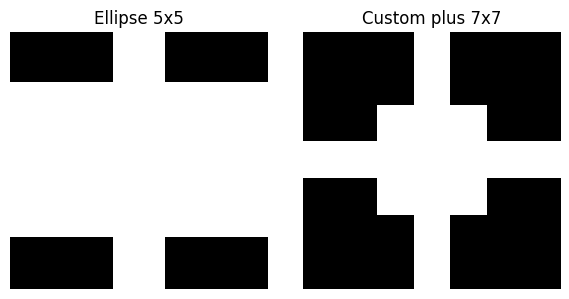

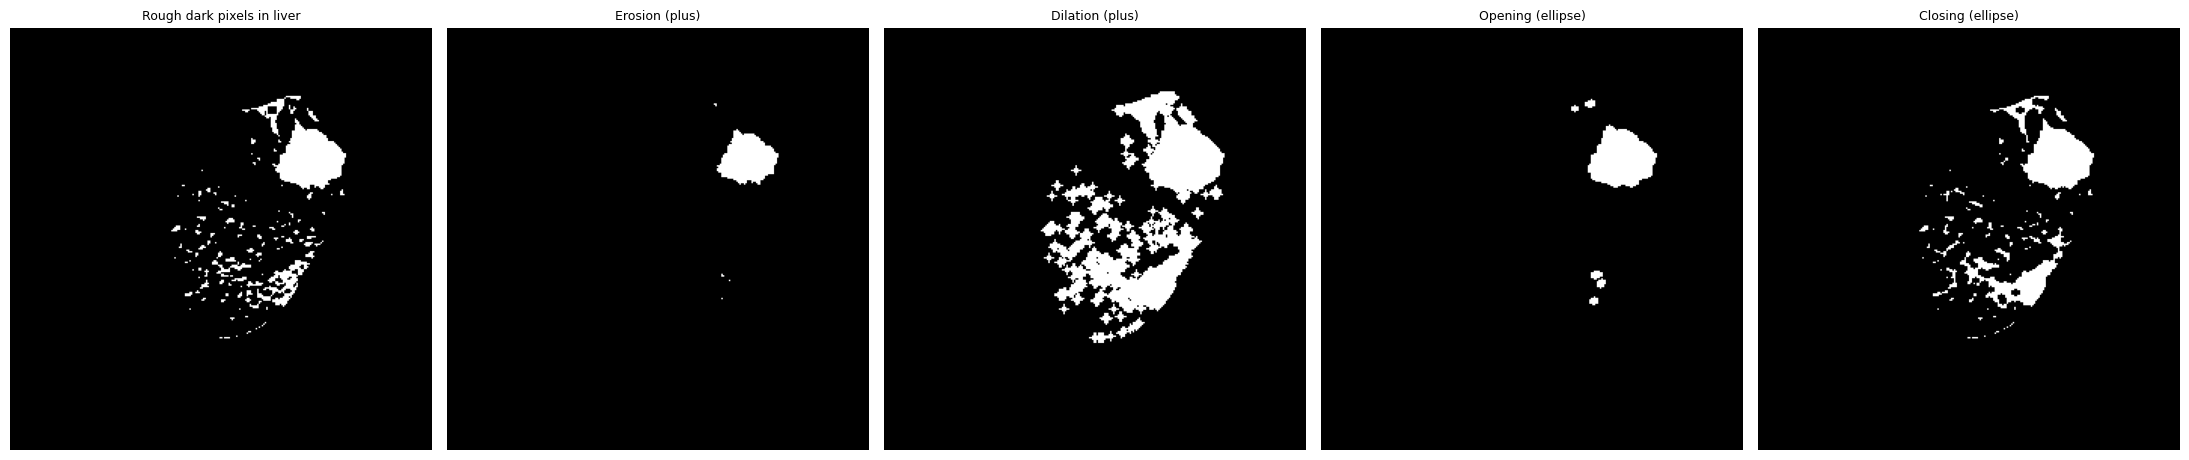

In [2]:
SE_ELLIPSE_5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
SE_PLUS_7 = np.zeros((7, 7), np.uint8); SE_PLUS_7[3, :] = 1; SE_PLUS_7[:, 3] = 1; SE_PLUS_7[2:5, 2:5] = 1  # thick plus
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for a, se, t in zip(ax, [SE_ELLIPSE_5, SE_PLUS_7], ["Ellipse 5x5", "Custom plus 7x7"]):
    a.imshow(se, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

def liver_roi(liver):
    """Shrink the liver a little so its dark border is not mistaken for tumour."""
    return cv2.erode(liver.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0

def remove_small(mask, min_area=30):
    lab = label(mask)
    out = np.zeros(mask.shape, bool)
    for r in regionprops(lab):
        if r.area >= min_area:
            out[lab == r.label] = True
    return out

roi = liver_roi(liver)
rough = ((img < np.median(img[roi]) - 30) & roi).astype(np.uint8)
ops = {"Rough dark pixels in liver": rough, "Erosion (plus)": cv2.erode(rough, SE_PLUS_7),
       "Dilation (plus)": cv2.dilate(rough, SE_PLUS_7), "Opening (ellipse)": cv2.morphologyEx(rough, cv2.MORPH_OPEN, SE_ELLIPSE_5),
       "Closing (ellipse)": cv2.morphologyEx(rough, cv2.MORPH_CLOSE, SE_ELLIPSE_5)}
r0, r1, c0, c1 = 120, 400, 40, 320
fig, ax = plt.subplots(1, 5, figsize=(22, 5))
for a, (t, m) in zip(ax, ops.items()):
    a.imshow(m[r0:r1, c0:c1], cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_morphology.png", dpi=120); plt.show()

**Method A: Multi-Otsu inside the liver.** Multi-Otsu looks only at the liver pixels and splits them into 3 brightness classes: dark (tumour), medium (liver), bright (vessels). The darkest class is the tumour candidate; opening removes specks, tiny blobs are dropped and holes are filled.

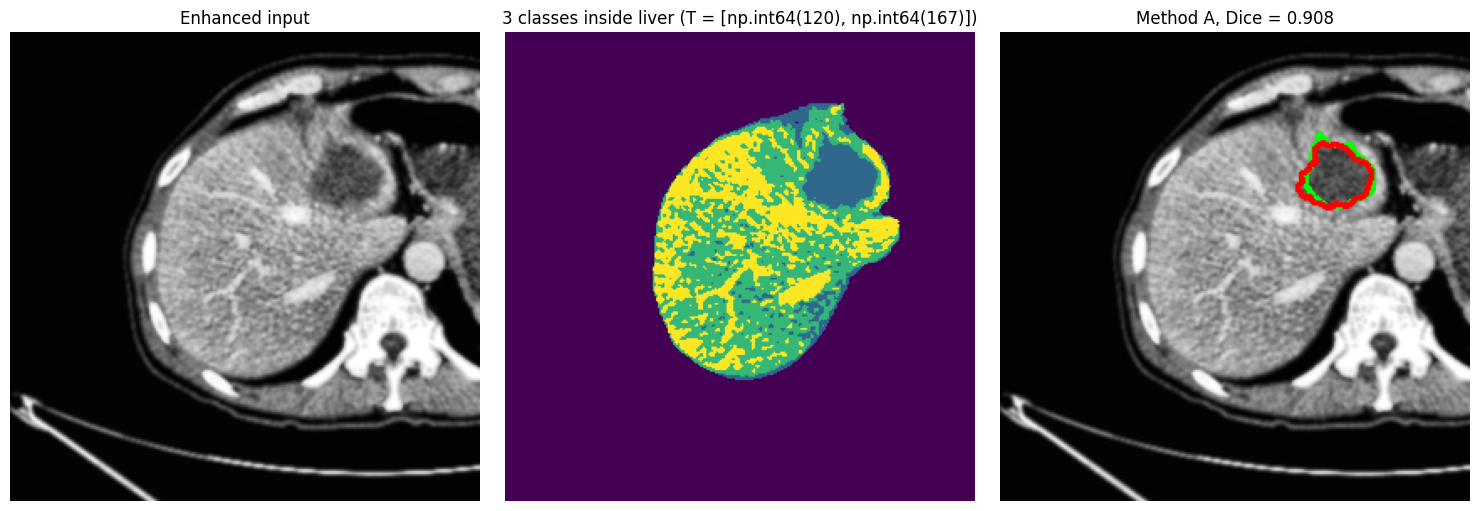

In [3]:
def segment_multiotsu(img, liver):
    roi = liver_roi(liver)
    if roi.sum() < 50:
        return np.zeros(img.shape, bool)
    t = threshold_multiotsu(img[roi], classes=3)          # thresholds from liver pixels only
    mask = (img < t[0]) & roi                              # darkest class
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, SE_ELLIPSE_5) > 0
    return ndi.binary_fill_holes(remove_small(mask))

t = threshold_multiotsu(img[liver_roi(liver)], classes=3)
classes = np.where(liver, np.digitize(img, bins=t) + 1, 0)
pred_a = segment_multiotsu(img, liver)
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img[r0:r1, c0:c1], cmap="gray"); ax[0].set_title("Enhanced input")
ax[1].imshow(classes[r0:r1, c0:c1], cmap="viridis"); ax[1].set_title(f"3 classes inside liver (T = {list(t)})")
ax[2].imshow(overlay(img, pred_a, gt)[r0:r1, c0:c1]); ax[2].set_title(f"Method A, Dice = {dice(pred_a, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_a_multiotsu.png", dpi=120); plt.show()

**Method B: seeded region growing.** 1) Seeds = the darkest pixel of each clearly dark spot (darker than liver median - 2.5 x std). 2) From each seed, grow while neighbours are within 30 of the region average, staying inside the liver. 3) A region that floods more than half the liver is rejected (it leaked).

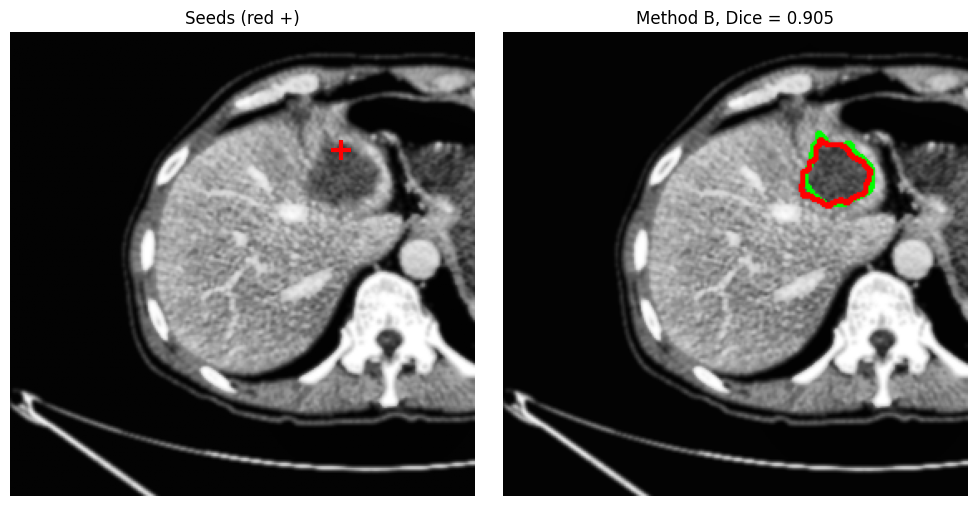

In [4]:
def region_grow(img, seed, tolerance, allowed=None):
    """Seeded region growing: start at the seed pixel and keep adding 4-neighbours whose
    brightness is within `tolerance` of the region's running average."""
    h, w = img.shape
    region = np.zeros((h, w), bool)
    region[seed] = True
    stack, total, count = [seed], float(img[seed]), 1
    while stack:
        y, x = stack.pop()
        for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            yy, xx = y + dy, x + dx
            if 0 <= yy < h and 0 <= xx < w and not region[yy, xx] and (allowed is None or allowed[yy, xx]):
                if abs(float(img[yy, xx]) - total / count) <= tolerance:
                    region[yy, xx] = True
                    stack.append((yy, xx))
                    total += float(img[yy, xx]); count += 1
    return region

K_DARK, TOLERANCE = 2.5, 30

def segment_region_growing(img, liver, return_seeds=False):
    roi = liver_roi(liver)
    out, seeds = np.zeros(img.shape, bool), []
    if roi.sum() < 50:
        return (out, seeds) if return_seeds else out
    smooth = cv2.GaussianBlur(img, (5, 5), 0)
    med, sd = np.median(smooth[roi]), smooth[roi].std()
    dark = cv2.morphologyEx(((smooth < med - K_DARK * sd) & roi).astype(np.uint8), cv2.MORPH_OPEN, SE_ELLIPSE_5) > 0
    for r in regionprops(label(dark)):
        if r.area < 30:
            continue
        seed = tuple(r.coords[np.argmin(smooth[tuple(r.coords.T)])])      # darkest pixel of the spot
        grown = region_grow(smooth, seed, TOLERANCE, roi)
        if grown.sum() < 0.5 * roi.sum():
            out |= grown; seeds.append(seed)
    out = ndi.binary_fill_holes(cv2.morphologyEx(out.astype(np.uint8), cv2.MORPH_CLOSE, SE_ELLIPSE_5) > 0)
    return (out, seeds) if return_seeds else out

pred_b, seeds = segment_region_growing(img, liver, return_seeds=True)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img[r0:r1, c0:c1], cmap="gray")
for s in seeds:
    ax[0].plot(s[1] - c0, s[0] - r0, "r+", markersize=15, mew=3)
ax[0].set_title("Seeds (red +)")
ax[1].imshow(overlay(img, pred_b, gt)[r0:r1, c0:c1]); ax[1].set_title(f"Method B, Dice = {dice(pred_b, gt):.3f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_method_b_regiongrow.png", dpi=120); plt.show()

In [5]:
rows = []
for f in files:
    sid, img, liver, gt = load(f)
    for method, fn in [("multiotsu", segment_multiotsu), ("regiongrow", segment_region_growing)]:
        pred = fn(img, liver)
        cv2.imwrite(f"{OUT}/{method}/{sid}_tumour_pred.png", pred.astype(np.uint8) * 255)
        rows.append({"slice": sid, "method": method, "Dice": dice(pred, gt), "IoU": iou(pred, gt), "GT tumour pixels": int(gt.sum())})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase2_metrics.csv", index=False)
print(results.groupby("method")[["Dice", "IoU"]].agg(["mean", "std", "min"]).round(3))
print("\nPer slice Dice:")
print(results.pivot(index="slice", columns="method", values="Dice").round(3))

             Dice                  IoU              
             mean    std    min   mean    std    min
method                                              
multiotsu   0.651  0.283  0.103  0.535  0.275  0.055
regiongrow  0.678  0.328  0.000  0.582  0.307  0.000

Per slice Dice:
method    multiotsu  regiongrow
slice                          
p22_s126      0.103       0.079
p22_s127      0.466       0.415
p22_s128      0.742       0.746
p22_s129      0.801       0.863
p22_s130      0.811       0.849
p22_s131      0.928       0.928
p22_s132      0.908       0.905
p22_s133      0.832       0.775
p22_s134      0.820       0.895
p22_s135      0.747       0.877
p22_s136      0.515       0.809
p22_s137      0.140       0.000


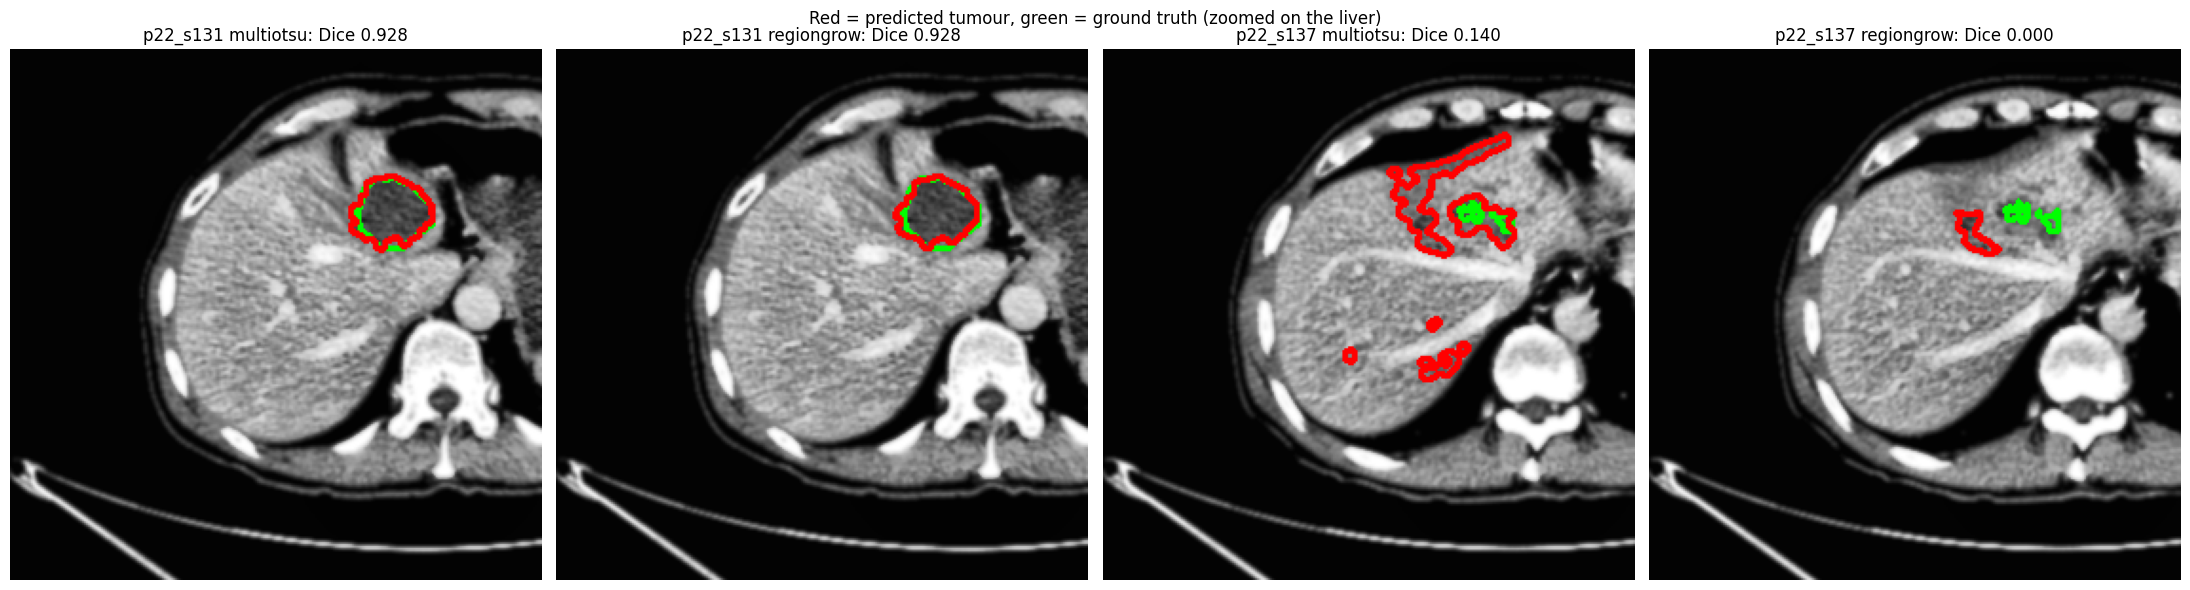

In [6]:
best_method = results.groupby("method")["Dice"].mean().idxmax()
d = results[results.method == best_method].set_index("slice")["Dice"]
best_sid, worst_sid = d.idxmax(), d.idxmin()
fig, ax = plt.subplots(1, 4, figsize=(22, 6))
for a, (s, method) in zip(ax, [(best_sid, "multiotsu"), (best_sid, "regiongrow"), (worst_sid, "multiotsu"), (worst_sid, "regiongrow")]):
    _, img, _, gt = load(f"{ENH}/{s}_enh.png")
    pred = cv2.imread(f"{OUT}/{method}/{s}_tumour_pred.png", 0) > 0
    a.imshow(overlay(img, pred, gt)[r0:r1, c0:c1]); a.axis("off"); a.set_title(f"{s} {method}: Dice {dice(pred, gt):.3f}")
plt.suptitle("Red = predicted tumour, green = ground truth (zoomed on the liver)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p2_overlays.png", dpi=120); plt.show()

In [7]:
# ---- failed cases: every slice where the best method scored Dice < 0.7, with the likely reason ----
def failure_reason(pred, gt):
    if pred.sum() == 0:
        return "missed completely: nothing was segmented"
    if gt.sum() < 300:
        return f"very small tumour on this slice ({int(gt.sum())} pixels), near the top or bottom of the organ"
    if pred.sum() > 1.5 * gt.sum():
        return "over-segmentation: the mask leaked into neighbouring tissue"
    if pred.sum() < 0.6 * gt.sum():
        return "under-segmentation: only part of the tumour was found"
    return "boundary mismatch: right place, but the outline differs from the ground truth"

best_method = results.groupby("method")["Dice"].mean().idxmax()
best = results[results.method == best_method].sort_values("Dice")
failed = best[best.Dice < 0.7]
lines = [f"# Phase 2 failed cases: {NAME} (tumour segmentation)", "",
         f"Best method: **{best_method}** (mean Dice {best.Dice.mean():.3f}). Slices with Dice < 0.7: {len(failed)} of {len(best)}.", "",
         "| Slice | Dice ({}) | Ground-truth pixels | Predicted pixels | Likely reason |".format(best_method),
         "|---|---|---|---|---|"]
for _, row in failed.iterrows():
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_tumour_pred.png", 0) > 0
    lines.append(f"| {row.slice} | {row.Dice:.3f} | {int(gt.sum())} | {int(pred.sum())} | {failure_reason(pred, gt)} |")
for _, row in failed.head(3).iterrows():                       # save overlays of the 3 worst
    r = load(f"{ENH}/{row.slice}_enh.png")
    img, gt = r[1], r[-1]
    pred = cv2.imread(f"{OUT}/{best_method}/{row.slice}_tumour_pred.png", 0) > 0
    cv2.imwrite(f"{FAILED}/{NAME}_{row.slice}_{best_method}_overlay.png", cv2.cvtColor(overlay(img, pred, gt), cv2.COLOR_RGB2BGR))
if failed.empty:
    lines.append("| - | - | - | - | no slice below 0.7 |")
lines += ["", "Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth)."]
open(f"{FAILED}/{NAME}_phase2_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

# Phase 2 failed cases: kritikaa (tumour segmentation)

Best method: **regiongrow** (mean Dice 0.678). Slices with Dice < 0.7: 3 of 12.

| Slice | Dice (regiongrow) | Ground-truth pixels | Predicted pixels | Likely reason |
|---|---|---|---|---|
| p22_s137 | 0.000 | 153 | 254 | very small tumour on this slice (153 pixels), near the top or bottom of the organ |
| p22_s126 | 0.079 | 57 | 1393 | very small tumour on this slice (57 pixels), near the top or bottom of the organ |
| p22_s127 | 0.415 | 441 | 1571 | over-segmentation: the mask leaked into neighbouring tissue |

Overlay images of the 3 worst slices are saved next to this file (red = predicted, green = ground truth).
